In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np

project_folder = Path(r"D:\electricity-tariff-optimisation")
processed_folder = project_folder / "data" / "processed"
database_file = processed_folder / "electricity_analysis.duckdb"

assert database_file.is_file(), "Prepared database was not found."

with duckdb.connect(
    str(database_file),
    read_only=True,
) as connection:
    design_intervals = connection.execute("""
        SELECT
            household_id,
            interval_start_utc,
            energy_kwh
        FROM analysis_consumption_2013
        WHERE interval_start_utc >= TIMESTAMP '2013-01-01'
          AND interval_start_utc < TIMESTAMP '2013-07-01'
    """).df()

assert len(design_intervals) == 248 * 181 * 48
assert design_intervals["household_id"].nunique() == 248

assert not design_intervals.duplicated(
    ["household_id", "interval_start_utc"]
).any()

assert np.isfinite(design_intervals["energy_kwh"]).all()
assert (design_intervals["energy_kwh"] >= 0).all()

print(f"Design households: {design_intervals['household_id'].nunique()}")
print(f"Design intervals: {len(design_intervals):,}")
print(f"Design energy (kWh): {design_intervals['energy_kwh'].sum():,.3f}")
print("Prepared database reused; raw CSV files were not rescanned.")
print("Validation-period consumption was not loaded.")

Design households: 248
Design intervals: 2,154,624
Design energy (kWh): 549,198.974
Prepared database reused; raw CSV files were not rescanned.
Validation-period consumption was not loaded.


In [2]:
local_start = pd.to_datetime(
    design_intervals["interval_start_utc"],
    utc=True,
).dt.tz_convert("Europe/London")

design_intervals["day_type"] = np.where(
    local_start.dt.dayofweek < 5,
    "Weekday",
    "Weekend",
)

design_intervals["slot"] = (
    local_start.dt.hour * 2
    + local_start.dt.minute // 30
)

household_profiles = (
    design_intervals
    .groupby(["household_id", "day_type", "slot"])
    .agg(
        mean_energy_kwh=("energy_kwh", "mean"),
        observed_intervals=("energy_kwh", "size"),
    )
    .reset_index()
)

household_profiles["time_label"] = (
    (household_profiles["slot"] // 2)
    .astype(str)
    .str.zfill(2)
    + ":"
    + ((household_profiles["slot"] % 2) * 30)
    .astype(str)
    .str.zfill(2)
)

profile_counts = household_profiles.groupby(
    ["household_id", "day_type"]
).size()

assert len(household_profiles) == 248 * 2 * 48
assert profile_counts.eq(48).all()
assert household_profiles["observed_intervals"].gt(0).all()
assert np.isfinite(household_profiles["mean_energy_kwh"]).all()

household_profiles.to_csv(
    processed_folder / "customer_design_daily_profiles_2013.csv",
    index=False,
)

print(f"Household profile rows: {len(household_profiles):,}")
print("Each household has 48 weekday and 48 weekend slots.")
print("Unit: mean kWh per observed half-hour interval.")
print("Bank holidays are treated as ordinary weekdays.")
print("Profiles use the existing UTC-defined design period.")
print("Customer profiles saved.")

display(household_profiles.head(10))

Household profile rows: 23,808
Each household has 48 weekday and 48 weekend slots.
Unit: mean kWh per observed half-hour interval.
Bank holidays are treated as ordinary weekdays.
Profiles use the existing UTC-defined design period.
Customer profiles saved.


,household_id,day_type,slot,mean_energy_kwh,observed_intervals,time_label
0,MAC000002,Weekday,0,0.275777,130,00:00
1,MAC000002,Weekday,1,0.262015,130,00:30
2,MAC000002,Weekday,2,0.230318,129,01:00
3,MAC000002,Weekday,3,0.193434,129,01:30
4,MAC000002,Weekday,4,0.158736,129,02:00
5,MAC000002,Weekday,5,0.135721,129,02:30
6,MAC000002,Weekday,6,0.118403,129,03:00
7,MAC000002,Weekday,7,0.114597,129,03:30
8,MAC000002,Weekday,8,0.111837,129,04:00
9,MAC000002,Weekday,9,0.104659,129,04:30


In [3]:
expected_columns = pd.MultiIndex.from_product(
    [["Weekday", "Weekend"], range(48)],
    names=["day_type", "slot"],
)

profile_matrix = (
    household_profiles
    .pivot(
        index="household_id",
        columns=["day_type", "slot"],
        values="mean_energy_kwh",
    )
    .reindex(columns=expected_columns)
    .sort_index()
)

assert profile_matrix.shape == (248, 96)
assert np.isfinite(profile_matrix.to_numpy()).all()
assert (profile_matrix >= 0).all().all()

household_profile_mean = profile_matrix.mean(axis=1)

assert household_profile_mean.gt(0).all()

normalised_profiles = profile_matrix.div(
    household_profile_mean,
    axis=0,
)

assert np.isfinite(normalised_profiles.to_numpy()).all()
assert np.allclose(
    normalised_profiles.mean(axis=1),
    1.0,
)

normalised_profiles.columns = [
    f"{day_type.lower()}_{slot:02d}"
    for day_type, slot in normalised_profiles.columns
]

normalised_profiles.to_csv(
    processed_folder / "customer_design_normalised_profiles_2013.csv"
)

print(f"Clustering input shape: {normalised_profiles.shape}")
print("Each household has 96 normalised profile features.")
print("A value of 1 represents the household profile mean.")
print("Weekday and weekend profiles receive equal feature weight.")
print("Validation-period data was not used.")

display(normalised_profiles.iloc[:5, :8].round(4))

Clustering input shape: (248, 96)
Each household has 96 normalised profile features.
A value of 1 represents the household profile mean.
Weekday and weekend profiles receive equal feature weight.
Validation-period data was not used.


,weekday_00,weekday_01,weekday_02,weekday_03,weekday_04,weekday_05,weekday_06,weekday_07
household_id,,,,,,,,
MAC000002,1.0706,1.0172,0.8941,0.7510,0.6163,0.5269,0.4597,0.4449
MAC000040,0.7066,0.7074,0.7089,0.7264,0.5978,0.6808,0.6711,0.7909
MAC000100,0.3505,0.3468,0.3455,0.3392,0.3274,0.3325,0.3341,0.3315
MAC000145,0.8962,0.8433,0.7410,0.7009,0.6553,0.6044,0.5813,0.5629
MAC000162,1.1770,1.0531,0.9600,0.9541,0.8898,0.7938,0.7342,0.6207


In [4]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

clustering_input = normalised_profiles.to_numpy()

candidate_models = {}
clustering_scores = []

for cluster_count in range(2, 7):
    model = KMeans(
        n_clusters=cluster_count,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(clustering_input)
    cluster_sizes = pd.Series(labels).value_counts()

    candidate_models[cluster_count] = model

    clustering_scores.append({
        "clusters": cluster_count,
        "silhouette_score": silhouette_score(
            clustering_input,
            labels,
        ),
        "inertia": model.inertia_,
        "smallest_cluster": int(cluster_sizes.min()),
        "largest_cluster": int(cluster_sizes.max()),
        "cluster_sizes": ", ".join(
            str(int(size))
            for size in cluster_sizes.sort_index()
        ),
    })

clustering_comparison = pd.DataFrame(clustering_scores)

clustering_comparison.to_csv(
    processed_folder / "design_clustering_comparison_2013.csv",
    index=False,
)

display(clustering_comparison.round(4))

print("Candidate cluster counts evaluated: 2 to 6.")
print("Final cluster count has not been selected.")
print("Validation-period outcomes were not used for selection.")

D:\anaconda\envs\tf_env\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\anaconda\envs\tf_env\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "D:\anaconda\envs\tf_env\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "D:\anaconda\envs\tf_env\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\anaconda\envs\tf_env\lib\subprocess.py", line 1420, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
D:\anaconda\envs\tf_env\lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWa

,clusters,silhouette_score,inertia,smallest_cluster,largest_cluster,cluster_sizes
0,2,0.6409,4034.1855,8,240,"240, 8"
1,3,0.1455,3573.7109,8,134,"106, 134, 8"
2,4,0.1425,3283.2904,4,126,"110, 8, 126, 4"
3,5,0.1155,3041.3412,1,108,"68, 108, 8, 1, 63"
4,6,0.1124,2850.9491,1,82,"58, 21, 82, 80, 1, 6"


Candidate cluster counts evaluated: 2 to 6.
Final cluster count has not been selected.
Validation-period outcomes were not used for selection.


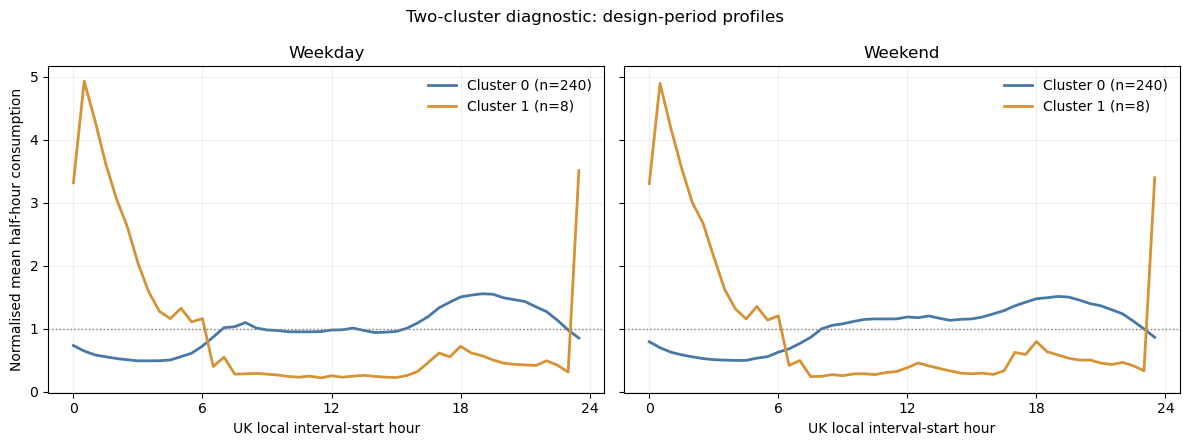

Households in the smaller cluster:


,cluster
household_id,
MAC000331,1
MAC000415,1
MAC004515,1
MAC004897,1
MAC004954,1
MAC005041,1
MAC005263,1
MAC005309,1


Diagnostic only; final segmentation has not been selected.


In [6]:
import matplotlib.pyplot as plt

two_cluster_model = candidate_models[2]

diagnostic_labels = pd.Series(
    two_cluster_model.labels_,
    index=normalised_profiles.index,
    name="cluster",
)

cluster_sizes = diagnostic_labels.value_counts().sort_index()

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharey=True,
)

hours = np.arange(48) / 2
colors = ["#4878A8", "#D69235"]

for ax, day_type in zip(axes, ["Weekday", "Weekend"]):
    columns = [
        f"{day_type.lower()}_{slot:02d}"
        for slot in range(48)
    ]

    for cluster_id, color in zip(cluster_sizes.index, colors):
        members = normalised_profiles.loc[
            diagnostic_labels == cluster_id,
            columns,
        ]

        ax.plot(
            hours,
            members.mean(axis=0).to_numpy(),
            color=color,
            linewidth=2,
            label=(
                f"Cluster {cluster_id} "
                f"(n={cluster_sizes.loc[cluster_id]})"
            ),
        )

    ax.axhline(1, color="grey", linestyle=":", linewidth=1)
    ax.set_title(day_type)
    ax.set_xlabel("UK local interval-start hour")
    ax.set_xticks([0, 6, 12, 18, 24])
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

axes[0].set_ylabel("Normalised mean half-hour consumption")

fig.suptitle("Two-cluster diagnostic: design-period profiles")
fig.tight_layout()
plt.show()

print("Households in the smaller cluster:")
small_cluster_id = cluster_sizes.idxmin()

display(
    diagnostic_labels.loc[
        diagnostic_labels == small_cluster_id
    ].to_frame()
)

print("Diagnostic only; final segmentation has not been selected.")

In [7]:
from sklearn.metrics import adjusted_rand_score

reference_labels = diagnostic_labels.to_numpy()
stability_rows = []

for seed in [0, 7, 21, 42, 99]:
    check_model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=20,
    )

    check_labels = check_model.fit_predict(clustering_input)
    sizes = pd.Series(check_labels).value_counts()

    stability_rows.append({
        "random_seed": seed,
        "adjusted_rand_index": adjusted_rand_score(
            reference_labels,
            check_labels,
        ),
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "inertia": check_model.inertia_,
    })

initialisation_stability = pd.DataFrame(stability_rows)

initialisation_stability.to_csv(
    processed_folder / "design_kmeans_initialisation_stability_2013.csv",
    index=False,
)

display(initialisation_stability.round(4))

print("Scope: sensitivity to random initialisation on the same data.")
print("Temporal stability and individual profiles are not yet checked.")

D:\anaconda\envs\tf_env\lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\anaconda\envs\tf_env\lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\anaconda\envs\tf_env\lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
D:\anaconda\envs\tf_env\lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows wi

,random_seed,adjusted_rand_index,smallest_cluster,largest_cluster,inertia
0,0,1.0,8,240,4034.1855
1,7,1.0,8,240,4034.1855
2,21,1.0,8,240,4034.1855
3,42,1.0,8,240,4034.1855
4,99,1.0,8,240,4034.1855


Scope: sensitivity to random initialisation on the same data.
Temporal stability and individual profiles are not yet checked.


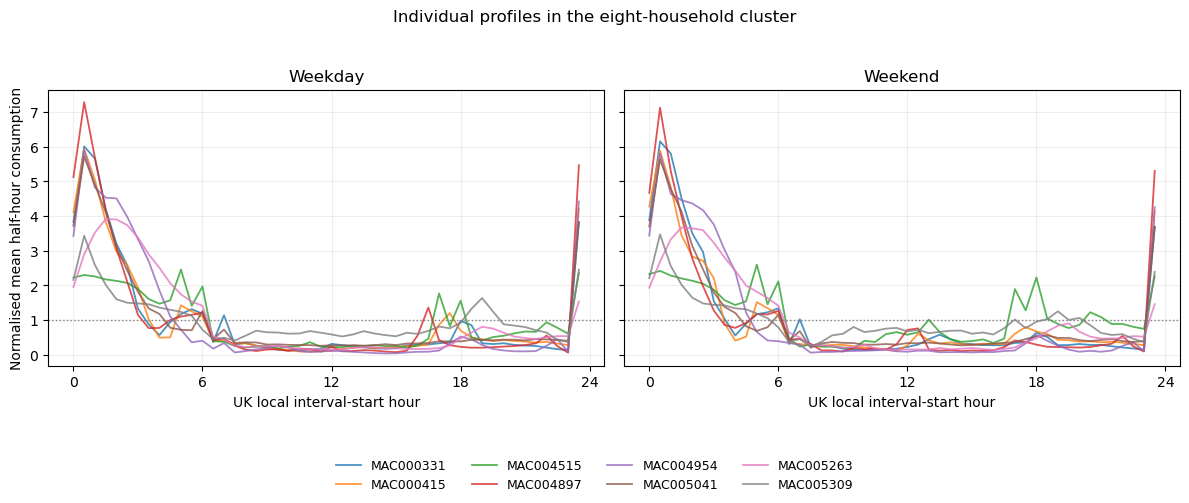

Profiles use design-period data only.
Night-time concentration does not identify appliance types.


In [8]:
small_cluster_ids = diagnostic_labels.index[
    diagnostic_labels == small_cluster_id
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True,
)

hours = np.arange(48) / 2

for ax, day_type in zip(axes, ["Weekday", "Weekend"]):
    columns = [
        f"{day_type.lower()}_{slot:02d}"
        for slot in range(48)
    ]

    for household_id in small_cluster_ids:
        ax.plot(
            hours,
            normalised_profiles.loc[
                household_id, columns
            ].to_numpy(),
            linewidth=1.3,
            alpha=0.8,
            label=household_id,
        )

    ax.axhline(
        1,
        color="grey",
        linestyle=":",
        linewidth=1,
    )

    ax.set_title(day_type)
    ax.set_xlabel("UK local interval-start hour")
    ax.set_xticks([0, 6, 12, 18, 24])
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Normalised mean half-hour consumption")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=9,
)

fig.suptitle("Individual profiles in the eight-household cluster")
fig.tight_layout(rect=[0, 0.15, 1, 0.95])
plt.show()

print("Profiles use design-period data only.")
print("Night-time concentration does not identify appliance types.")

In [9]:
monthly_intervals = design_intervals.copy()

utc_start = pd.to_datetime(
    monthly_intervals["interval_start_utc"],
    utc=True,
)

monthly_intervals["month_utc"] = utc_start.dt.strftime("%Y-%m")

monthly_profiles = (
    monthly_intervals
    .groupby(["month_utc", "household_id", "day_type", "slot"])
    ["energy_kwh"]
    .mean()
    .unstack(["day_type", "slot"])
    .reindex(columns=expected_columns)
)

assert np.isfinite(monthly_profiles.to_numpy()).all()

monthly_means = monthly_profiles.mean(axis=1)
usable_profiles = monthly_profiles.loc[monthly_means > 0]

monthly_normalised = usable_profiles.div(
    monthly_means.loc[usable_profiles.index],
    axis=0,
)

monthly_assignments = pd.Series(
    two_cluster_model.predict(monthly_normalised.to_numpy()),
    index=monthly_normalised.index,
    name="monthly_cluster",
).reset_index()

monthly_assignments["full_design_cluster"] = (
    monthly_assignments["household_id"].map(diagnostic_labels)
)

monthly_assignments["same_as_full_design"] = (
    monthly_assignments["monthly_cluster"]
    == monthly_assignments["full_design_cluster"]
)

small_group_monthly = (
    monthly_assignments.loc[
        monthly_assignments["household_id"].isin(small_cluster_ids)
    ]
    .pivot(
        index="household_id",
        columns="month_utc",
        values="monthly_cluster",
    )
    .reindex(index=small_cluster_ids)
)

monthly_assignments.to_csv(
    processed_folder / "design_monthly_cluster_assignments_2013.csv",
    index=False,
)

print(f"Reference small-cluster label: {small_cluster_id}")
print(
    "Zero-consumption monthly profiles excluded:",
    int((monthly_means == 0).sum()),
)
print("Monthly assignments for the eight-household group:")
display(small_group_monthly)

print("Same-model consistency within the design period only.")
print("Missing cells indicate excluded or unavailable monthly profiles.")
print("This is not an independent future-period validation.")

Reference small-cluster label: 1
Zero-consumption monthly profiles excluded: 0
Monthly assignments for the eight-household group:


month_utc,2013-01,2013-02,2013-03,2013-04,2013-05,2013-06
household_id,,,,,,
MAC000331,1,1,1,1,1,1
MAC000415,1,1,1,1,1,1
MAC004515,1,1,1,0,0,0
MAC004897,1,1,1,1,1,1
MAC004954,1,1,1,1,1,1
MAC005041,1,1,1,1,1,1
MAC005263,1,1,1,1,1,1
MAC005309,1,1,1,1,0,0


Same-model consistency within the design period only.
Missing cells indicate excluded or unavailable monthly profiles.
This is not an independent future-period validation.


In [10]:
cluster_assignments = diagnostic_labels.rename(
    "design_cluster"
).to_frame()

cluster_assignments["profile_group"] = np.where(
    cluster_assignments["design_cluster"] == small_cluster_id,
    "Night-concentrated profile",
    "Other consumption profiles",
)

monthly_consistency = (
    monthly_assignments
    .groupby("household_id")
    .agg(
        months_evaluated=("monthly_cluster", "size"),
        months_matching_design=(
            "same_as_full_design", "sum"
        ),
    )
)

cluster_assignments = cluster_assignments.join(
    monthly_consistency,
    validate="one_to_one",
)

cluster_assignments["monthly_agreement_pct"] = (
    cluster_assignments["months_matching_design"]
    / cluster_assignments["months_evaluated"]
    * 100
)

assert len(cluster_assignments) == 248
assert cluster_assignments["months_evaluated"].eq(6).all()

cluster_assignments.to_csv(
    processed_folder / "customer_design_cluster_assignments_2013.csv"
)

cluster_summary = (
    cluster_assignments
    .groupby("profile_group")
    .agg(
        households=("design_cluster", "size"),
        median_monthly_agreement_pct=(
            "monthly_agreement_pct", "median"
        ),
        households_matching_all_months=(
            "months_matching_design",
            lambda values: int(values.eq(6).sum()),
        ),
    )
)

display(cluster_summary)
display(cluster_assignments.loc[small_cluster_ids])

print("Exploratory profile groups saved.")
print("Monthly agreement is an in-design consistency measure.")
print("Tariff prices and switching assignments remain unchanged.")

,households,median_monthly_agreement_pct,households_matching_all_months
profile_group,,,
Night-concentrated profile,8,100.0,6
Other consumption profiles,240,100.0,240


,design_cluster,profile_group,months_evaluated,months_matching_design,monthly_agreement_pct
household_id,,,,,
MAC000331,1,Night-concentrated profile,6,6,100.000000
MAC000415,1,Night-concentrated profile,6,6,100.000000
MAC004515,1,Night-concentrated profile,6,3,50.000000
MAC004897,1,Night-concentrated profile,6,6,100.000000
MAC004954,1,Night-concentrated profile,6,6,100.000000
MAC005041,1,Night-concentrated profile,6,6,100.000000
MAC005263,1,Night-concentrated profile,6,6,100.000000
MAC005309,1,Night-concentrated profile,6,4,66.666667


Exploratory profile groups saved.
Monthly agreement is an in-design consistency measure.
Tariff prices and switching assignments remain unchanged.


In [11]:
import json
import joblib
from importlib.metadata import version

model_folder = project_folder / "models"
model_folder.mkdir(parents=True, exist_ok=True)

model_file = model_folder / "design_profile_kmeans_2013.joblib"
metadata_file = model_folder / "design_profile_kmeans_2013.json"

joblib.dump(two_cluster_model, model_file)

model_metadata = {
    "model_type": "KMeans",
    "purpose": "Exploratory consumption-profile grouping",
    "training_period": {
        "start_utc": "2013-01-01T00:00:00Z",
        "end_exclusive_utc": "2013-07-01T00:00:00Z"
    },
    "households": int(len(normalised_profiles)),
    "n_clusters": 2,
    "random_state": 42,
    "n_init": 20,
    "feature_columns": normalised_profiles.columns.tolist(),
    "normalisation": (
        "Divide each household's 96 mean half-hour values "
        "by their combined mean"
    ),
    "timezone": "Europe/London",
    "day_types": "Monday-Friday versus Saturday-Sunday",
    "profile_labels": {
        str(cluster_id): (
            "Night-concentrated profile"
            if cluster_id == small_cluster_id
            else "Other consumption profiles"
        )
        for cluster_id in range(2)
    },
    "scikit_learn_version": version("scikit-learn"),
    "limitations": [
        "The larger group contains diverse consumption profiles.",
        "Monthly agreement is measured within the design period.",
        "Profiles do not identify appliances or household demographics.",
        "Cluster membership does not determine tariff assignment."
    ]
}

metadata_file.write_text(
    json.dumps(model_metadata, indent=2) + "\n",
    encoding="utf-8",
)

reloaded_model = joblib.load(model_file)

assert np.array_equal(
    reloaded_model.predict(normalised_profiles.to_numpy()),
    diagnostic_labels.to_numpy(),
)

print(f"Model saved: {model_file}")
print(f"Metadata saved: {metadata_file}")
print("Reloaded model predictions: PASS")
print("Only load joblib model files from trusted sources.")

Model saved: D:\electricity-tariff-optimisation\models\design_profile_kmeans_2013.joblib
Metadata saved: D:\electricity-tariff-optimisation\models\design_profile_kmeans_2013.json
Reloaded model predictions: PASS
Only load joblib model files from trusted sources.


In [12]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np

project_folder = Path(r"D:\electricity-tariff-optimisation")
database_file = (
    project_folder / "data" / "processed"
    / "electricity_analysis.duckdb"
)

with duckdb.connect(str(database_file), read_only=True) as connection:
    validation_intervals = connection.execute("""
        SELECT
            household_id,
            interval_start_utc,
            energy_kwh
        FROM analysis_consumption_2013
        WHERE interval_start_utc >= TIMESTAMP '2013-07-01 00:00:00'
          AND interval_start_utc < TIMESTAMP '2014-01-01 00:00:00'
        ORDER BY household_id, interval_start_utc
    """).fetchdf()

validation_intervals["interval_start_utc"] = pd.to_datetime(
    validation_intervals["interval_start_utc"],
    utc=True,
)

expected_households = set(normalised_profiles.index)
actual_households = set(validation_intervals["household_id"])

assert actual_households == expected_households, \
    "Validation households do not match the design sample."

assert not validation_intervals.duplicated(
    ["household_id", "interval_start_utc"]
).any(), "Duplicate household intervals found."

energy = validation_intervals["energy_kwh"]
assert np.isfinite(energy.to_numpy()).all(), \
    "Missing or non-finite energy values found."
assert energy.ge(0).all(), "Negative energy values found."

expected_times = pd.date_range(
    start="2013-07-01",
    end="2014-01-01",
    freq="30min",
    inclusive="left",
    tz="UTC",
)

assert validation_intervals["interval_start_utc"].isin(
    expected_times
).all(), "Unexpected interval timestamps found."

interval_counts = validation_intervals.groupby(
    "household_id"
).size()

assert interval_counts.eq(len(expected_times)).all(), \
    "Some households have incomplete validation-period records."

print(f"Validation households: {len(actual_households):,}")
print(f"Validation intervals: {len(validation_intervals):,}")
print(f"Intervals per household: {len(expected_times):,}")
print(f"Validation energy (kWh): {energy.sum():,.3f}")
print("Household and interval completeness checks: PASS")
print("The existing model has not been retrained.")
print("Validation cluster predictions have not yet been made.")

Validation households: 248
Validation intervals: 2,190,336
Intervals per household: 8,832
Validation energy (kWh): 489,289.068
Household and interval completeness checks: PASS
The existing model has not been retrained.
Validation cluster predictions have not yet been made.


In [13]:
import json

metadata_file = (
    project_folder / "models"
    / "design_profile_kmeans_2013.json"
)
model_metadata = json.loads(
    metadata_file.read_text(encoding="utf-8")
)

validation_local = validation_intervals[
    "interval_start_utc"
].dt.tz_convert("Europe/London")

validation_intervals["day_type"] = np.where(
    validation_local.dt.dayofweek < 5,
    "Weekday",
    "Weekend",
)
validation_intervals["slot"] = (
    validation_local.dt.hour * 2
    + validation_local.dt.minute // 30
)

validation_daily_profiles = (
    validation_intervals
    .groupby(["household_id", "day_type", "slot"])
    ["energy_kwh"]
    .mean()
    .rename("mean_energy_kwh")
    .reset_index()
)

expected_profile_columns = pd.MultiIndex.from_product(
    [["Weekday", "Weekend"], range(48)],
    names=["day_type", "slot"],
)

validation_profile_matrix = (
    validation_daily_profiles
    .pivot(
        index="household_id",
        columns=["day_type", "slot"],
        values="mean_energy_kwh",
    )
    .reindex(
        index=normalised_profiles.index,
        columns=expected_profile_columns,
    )
)

assert np.isfinite(
    validation_profile_matrix.to_numpy()
).all(), "Missing or non-finite profile features found."

validation_profile_means = validation_profile_matrix.mean(axis=1)

assert validation_profile_means.gt(0).all(), \
    "Zero-consumption profiles cannot be normalised."

validation_normalised_profiles = validation_profile_matrix.div(
    validation_profile_means,
    axis=0,
)

validation_normalised_profiles.columns = [
    f"{day_type.lower()}_{slot:02d}"
    for day_type, slot in expected_profile_columns
]

assert list(validation_normalised_profiles.columns) == (
    model_metadata["feature_columns"]
), "Feature order does not match the saved model metadata."

assert list(validation_normalised_profiles.columns) == list(
    normalised_profiles.columns
), "Validation and design feature columns differ."

assert np.allclose(
    validation_normalised_profiles.mean(axis=1),
    1.0,
), "Normalised profile means are not equal to one."

print(
    "Validation feature shape:",
    validation_normalised_profiles.shape,
)
print("Saved feature order: PASS")
print("Normalisation check: PASS")
print("Profiles use validation-period consumption only.")
print("Weekday and weekend profiles receive equal feature weight.")
print("No model fitting or cluster prediction was performed.")

Validation feature shape: (248, 96)
Saved feature order: PASS
Normalisation check: PASS
Profiles use validation-period consumption only.
Weekday and weekend profiles receive equal feature weight.
No model fitting or cluster prediction was performed.


In [14]:
import joblib

model_file = (
    project_folder / "models"
    / "design_profile_kmeans_2013.joblib"
)

# Load only the trusted model created in this project.
saved_profile_model = joblib.load(model_file)

design_predictions = saved_profile_model.predict(
    normalised_profiles.to_numpy()
)
validation_predictions = saved_profile_model.predict(
    validation_normalised_profiles.to_numpy()
)

assert np.array_equal(
    design_predictions,
    diagnostic_labels.reindex(normalised_profiles.index).to_numpy(),
), "Reloaded model does not reproduce the original design labels."

profile_labels = {
    int(cluster_id): label
    for cluster_id, label
    in model_metadata["profile_labels"].items()
}

period_comparison = pd.DataFrame(
    {
        "design_cluster": design_predictions,
        "validation_cluster": validation_predictions,
    },
    index=normalised_profiles.index,
)
period_comparison.index.name = "household_id"

period_comparison["design_profile_group"] = (
    period_comparison["design_cluster"].map(profile_labels)
)
period_comparison["validation_profile_group"] = (
    period_comparison["validation_cluster"].map(profile_labels)
)
period_comparison["same_group"] = (
    period_comparison["design_cluster"]
    == period_comparison["validation_cluster"]
)

retention_summary = (
    period_comparison
    .groupby("design_profile_group")
    .agg(
        households=("same_group", "size"),
        retained_group=("same_group", "sum"),
    )
)
retention_summary["changed_group"] = (
    retention_summary["households"]
    - retention_summary["retained_group"]
)
retention_summary["retention_pct"] = (
    100
    * retention_summary["retained_group"]
    / retention_summary["households"]
)

transition_table = pd.crosstab(
    period_comparison["design_profile_group"],
    period_comparison["validation_profile_group"],
).reindex(
    index=list(profile_labels.values()),
    columns=list(profile_labels.values()),
    fill_value=0,
)

print("Reloaded design predictions: PASS")
print("\nH1-to-H2 group transitions:")
display(transition_table)

print("\nRetention by original design-period group:")
display(retention_summary.round(2))

print("\nHouseholds whose group changed:")
display(period_comparison.loc[~period_comparison["same_group"]])

print("The saved model was applied without retraining.")
print("Retention measures cross-period consistency, not accuracy.")
print("Seasonal or behavioural changes may cause group transitions.")
print("Tariff prices and customer assignments remain unchanged.")

Reloaded design predictions: PASS

H1-to-H2 group transitions:


validation_profile_group,Other consumption profiles,Night-concentrated profile
design_profile_group,,
Other consumption profiles,240,0
Night-concentrated profile,2,6



Retention by original design-period group:


,households,retained_group,changed_group,retention_pct
design_profile_group,,,,
Night-concentrated profile,8,6,2,75.0
Other consumption profiles,240,240,0,100.0



Households whose group changed:


,design_cluster,validation_cluster,design_profile_group,validation_profile_group,same_group
household_id,,,,,
MAC004515,1,0,Night-concentrated profile,Other consumption profiles,False
MAC005309,1,0,Night-concentrated profile,Other consumption profiles,False


The saved model was applied without retraining.
Retention measures cross-period consistency, not accuracy.
Seasonal or behavioural changes may cause group transitions.
Tariff prices and customer assignments remain unchanged.


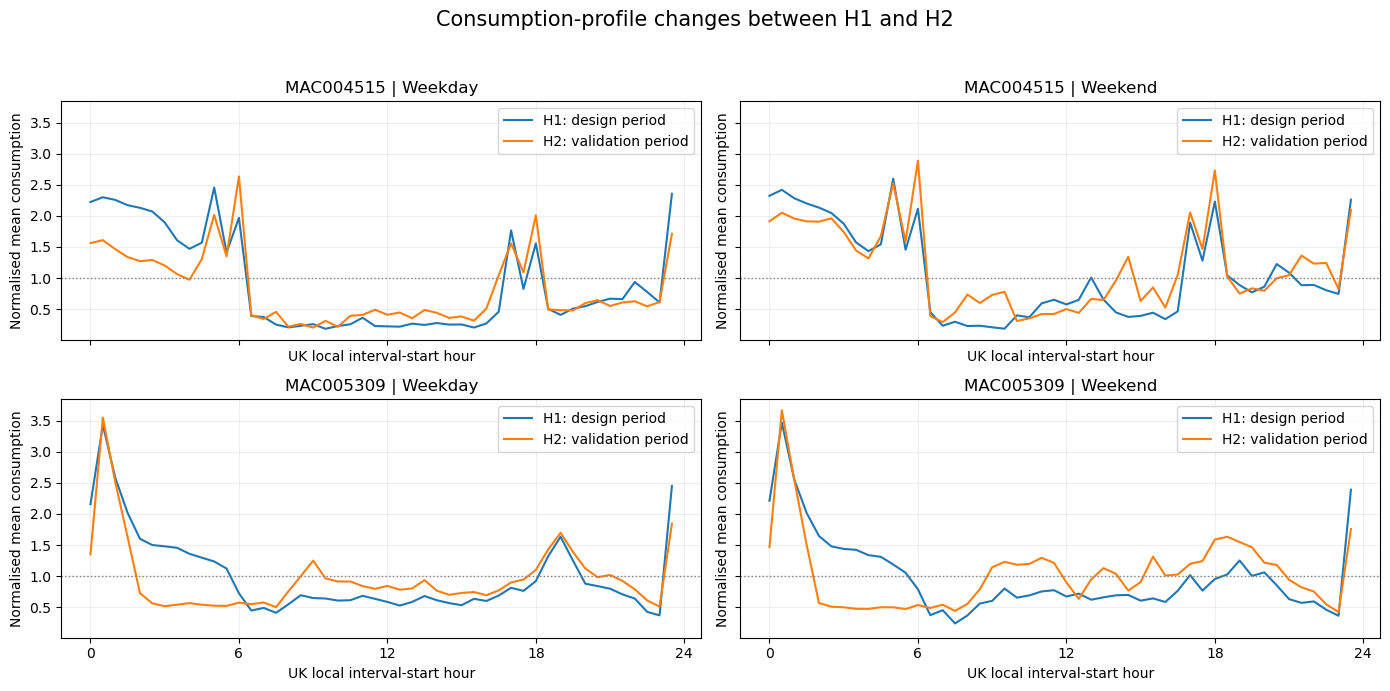

Each half-year profile is normalised by its own 96-feature mean.
Curves compare consumption shape, not absolute energy use.
Observed changes do not establish their cause.


In [15]:
import matplotlib.pyplot as plt

changed_ids = period_comparison.index[
    ~period_comparison["same_group"]
].tolist()

assert changed_ids, "No households changed groups."

hours = np.arange(48) / 2

fig, axes = plt.subplots(
    len(changed_ids),
    2,
    figsize=(14, 3.5 * len(changed_ids)),
    squeeze=False,
    sharex=True,
    sharey=True,
)

for row, household_id in enumerate(changed_ids):
    for col, day_type in enumerate(["weekday", "weekend"]):
        feature_columns = [
            f"{day_type}_{slot:02d}"
            for slot in range(48)
        ]

        ax = axes[row, col]

        ax.plot(
            hours,
            normalised_profiles.loc[
                household_id, feature_columns
            ].to_numpy(dtype=float),
            label="H1: design period",
        )
        ax.plot(
            hours,
            validation_normalised_profiles.loc[
                household_id, feature_columns
            ].to_numpy(dtype=float),
            label="H2: validation period",
        )

        ax.axhline(
            1,
            color="grey",
            linestyle=":",
            linewidth=1,
        )
        ax.set_title(
            f"{household_id} | {day_type.title()}"
        )
        ax.set_xlabel("UK local interval-start hour")
        ax.set_ylabel("Normalised mean consumption")
        ax.set_xticks([0, 6, 12, 18, 24])
        ax.grid(alpha=0.2)
        ax.legend()

fig.suptitle(
    "Consumption-profile changes between H1 and H2",
    fontsize=15,
)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("Each half-year profile is normalised by its own 96-feature mean.")
print("Curves compare consumption shape, not absolute energy use.")
print("Observed changes do not establish their cause.")

In [16]:
processed_folder = project_folder / "data" / "processed"
validation_report_folder = (
    project_folder / "reports" / "validation"
)
validation_report_folder.mkdir(parents=True, exist_ok=True)

period_comparison.to_csv(
    processed_folder / "customer_profile_h1_h2_comparison_2013.csv"
)

retention_summary.to_csv(
    validation_report_folder / "profile_group_h2_retention_2013.csv"
)

transition_table.to_csv(
    validation_report_folder / "profile_group_h1_h2_transitions_2013.csv"
)

validation_normalised_profiles.to_csv(
    processed_folder / "customer_validation_normalised_profiles_2013.csv"
)

consistency_summary = {
    "assessment": "Fixed-model H1-to-H2 profile consistency",
    "households": int(len(period_comparison)),
    "unchanged_households": int(
        period_comparison["same_group"].sum()
    ),
    "changed_households": int(
        (~period_comparison["same_group"]).sum()
    ),
    "overall_consistency_pct": float(
        100 * period_comparison["same_group"].mean()
    ),
    "changed_household_ids": list(changed_ids),
    "model_retrained": False,
    "limitations": [
        "Consistency is not classification accuracy.",
        "The overall percentage is dominated by the larger group.",
        "Half-year averages can conceal monthly variation.",
        "Profile changes do not establish their causes.",
        "The larger group contains diverse consumption profiles.",
        "Results concern the existing historical household sample.",
    ],
}

summary_file = (
    validation_report_folder
    / "profile_group_cross_period_summary_2013.json"
)
summary_file.write_text(
    json.dumps(consistency_summary, indent=2),
    encoding="utf-8",
)

print("Cross-period comparison and validation features saved.")
print(
    "Overall cross-period consistency: "
    f"{consistency_summary['overall_consistency_pct']:.2f}%"
)
print("Night-concentrated group retention: 6 of 8 households (75%).")
print("This is a consistency assessment, not an accuracy estimate.")
print("Tariff prices and switching assignments remain unchanged.")

Cross-period comparison and validation features saved.
Overall cross-period consistency: 99.19%
Night-concentrated group retention: 6 of 8 households (75%).
This is a consistency assessment, not an accuracy estimate.
Tariff prices and switching assignments remain unchanged.
